# Modelo de Regresión Logística - **“Sistema predictivo de la intención declarada de estudiar en áreas de Informática / Tecnología / Programación / Ciencia de Datos según factores socioeducativos, actitudinales y de preferencias en jóvenes argentinos de 16 a 18 años que piensan seguir estudiando”**
## Autor: Mauricio Turdo
## Carrera: Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial

Fuente de datos para este proyecto: **"Actitud de la juventud hacia las profesiones STEM"** (informe preliminar)  
https://www.argentina.gob.ar/sites/default/files/informe_preliminar_jovenes_stem.pdf

### Conjunto de datos

| Campo | Detalle |
| :--- | :--- |
| **Nombre** | Actitud de los jóvenes hacia las profesiones STEM |
| **Organismo** | IDES-KNAC para el MINCyT |
| **Período de relevamiento** | Del 17 de julio al 19 de agosto de 2023 |
| **Fuente** | Portal oficial `argentina.gob.ar` (formato CSV). El enlace de descarga está en la notebook de EDA |
| **Dimensiones iniciales** | 2.891 registros y 217 columnas |
| **Población de modelado** | 2.119 jóvenes: 1.695 para entrenamiento y 424 para prueba (preparados en la notebook de EDA) |


### Contenido del Documento

1. Problema a resolver y origen de los datos
2. Momento de la predicción
3. Carga de los datos
4. Exploración: lo más importante que mostró el EDA
5. Modelo de referencia básico
6. El modelo: regresión logística
7. Resultados: hiperparámetros a utilizar
8. Umbral de decisión
9. Variables que más pesan en el modelo
10. Guardar el modelo
11. Conclusiones

**Cómo ejecutarla:** en el repositorio, con los archivos que genera la notebook de EDA en `data/interim/` y `data/processed/`. En Colab, subir `X_train.csv`, `X_test.csv`, `y_train.csv` e `y_test.csv` a `/content/` (panel de archivos de la izquierda) y ejecutar de arriba hacia abajo.

## 1. Problema a resolver y origen de los datos

**Problema:** promover las vocaciones en Informática, Tecnología, Programación y Ciencia de Datos es importante para el desarrollo del país. Saber qué respuestas se asocian con querer estudiar esas áreas ayuda a entender qué influye en la elección y a decidir dónde invertir recursos y qué acciones hacer para acercar a más jóvenes.

**Pregunta:** ¿se puede predecir, con las respuestas de una encuesta, si un joven **declara** que piensa estudiar Informática, Tecnología, Programación o Ciencia de Datos? Es un problema de **clasificación binaria**.

- **Datos:** encuesta IDES-KNAC / MINCyT 2023, online y con muestra no probabilística. Cada fila es un joven de 16 a 18 años.
- **Qué se predice (`y`):** `y = 1` si marcó esa opción en la pregunta `P13_9` (Informática, Tecnología, Programación o Ciencia de Datos); `y = 0` si no. Esto último no significa que las rechace: puede haber elegido otra área.
- **Con qué se predice (`X`):** 125 respuestas de la encuesta (gustos por las materias, intereses, actividades, sexo, edad, entre otras). Se excluyeron `P15`, `P16` y `P18` porque dependen de la respuesta objetivo.
- **Población:** 2.891 encuestados → 2.386 que piensan seguir estudiando, cursen o no el secundario (solo ellos respondieron `P13`) → **2.119** al excluir a 267 que respondieron "No sé aún" qué estudiar. Por eso el modelo **no sirve para jóvenes indecisos**. El 16,9 % tiene `y = 1`.
- **Evaluación:** el modelo aprende con 1.695 jóvenes (entrenamiento) y se mide con otros 424 que no vio (prueba).

## 2. Momento de la predicción
- **Cuándo:** con jóvenes de 16 a 18 años que piensan seguir estudiando, para estimar qué tan probable es que declaren interés en estas áreas y qué respuestas se asocian con ese interés y así orientar recursos y acciones.
- **Con qué datos:** respuestas de la encuesta sobre gustos, intereses, contexto, sexo y edad.
- **Qué no es:** no predice qué carrera va a estudiar realmente, solo la intención que declara en la encuesta.
- **Límite:** predictores y objetivo se respondieron al mismo tiempo, sin seguimiento en el tiempo, así que no se sabe si lo declarado coincide con lo que después estudian.

## 3. Carga de los datos

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tamaño de los gráficos
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['figure.dpi'] = 80

# Los archivos están en data/ (repositorio) o en /content/ (Colab)
# Raíz del proyecto: '..' si la notebook está en notebooks/; '.' si se ejecuta desde la raíz o en Colab
raiz = '..' if os.path.exists('../data/interim') else '.'
carpeta_interim = f'{raiz}/data/interim' if os.path.exists(f'{raiz}/data/interim/X_train.csv') else '/content'
carpeta_processed = f'{raiz}/data/processed' if os.path.exists(f'{raiz}/data/processed/y_train.csv') else '/content'

X_train = pd.read_csv(f'{carpeta_interim}/X_train.csv', index_col=0)
X_test = pd.read_csv(f'{carpeta_interim}/X_test.csv', index_col=0)
y_train = pd.read_csv(f'{carpeta_processed}/y_train.csv', index_col=0)['y']
y_test = pd.read_csv(f'{carpeta_processed}/y_test.csv', index_col=0)['y']

# Control: cada fila de X tiene su y (mismo índice)
assert (X_train.index == y_train.index).all() and (X_test.index == y_test.index).all()
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print(f'% de y=1 en entrenamiento: {y_train.mean() * 100:.1f}% | en prueba: {y_test.mean() * 100:.1f}%')

Entrenamiento: (1695, 125) | Prueba: (424, 125)
% de y=1 en entrenamiento: 16.9% | en prueba: 17.0%


## 4. Exploración de los datos
Tres gráficos con datos de entrenamiento que muestran hallazgos importantes:

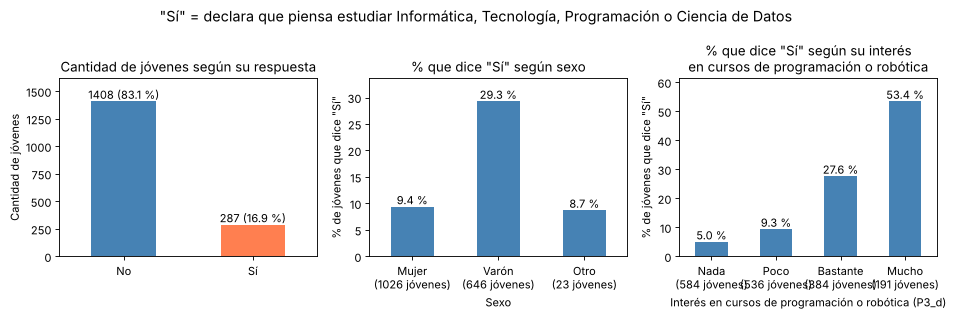

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle('"Sí" = declara que piensa estudiar Informática, Tecnología, Programación o Ciencia de Datos', fontsize=13)

# 1. Cuántos jóvenes hay en cada clase
cantidades = y_train.value_counts().sort_index()
cantidades.index = ['No', 'Sí']
cantidades.plot(kind='bar', ax=ejes[0], color=['steelblue', 'coral'])
ejes[0].bar_label(ejes[0].containers[0], labels=[f'{n} ({n / len(y_train) * 100:.1f} %)' for n in cantidades])
ejes[0].set_title('Cantidad de jóvenes según su respuesta')
ejes[0].set_xlabel('')
ejes[0].set_ylabel('Cantidad de jóvenes')
ejes[0].set_ylim(0, cantidades.max() * 1.15)
ejes[0].tick_params(axis='x', rotation=0)

# 2. % que dice "Sí" según sexo
por_sexo = y_train.groupby(X_train['F4.SEXO']).mean() * 100
casos_sexo = X_train['F4.SEXO'].value_counts().sort_index()
por_sexo.index = [f'{n}\n({c} jóvenes)' for n, c in zip(['Mujer', 'Varón', 'Otro'], casos_sexo)]
por_sexo.plot(kind='bar', ax=ejes[1], color='steelblue')
ejes[1].bar_label(ejes[1].containers[0], fmt='%.1f %%')
ejes[1].set_title('% que dice "Sí" según sexo')
ejes[1].set_xlabel('Sexo')
ejes[1].set_ylabel('% de jóvenes que dice "Sí"')
ejes[1].set_ylim(0, por_sexo.max() * 1.15)
ejes[1].tick_params(axis='x', rotation=0)

# 3. % que dice "Sí" según interés en cursos de programación o robótica (P3_d)
por_interes = y_train.groupby(X_train['P3_d']).mean() * 100
casos_interes = X_train['P3_d'].value_counts().sort_index()
por_interes.index = [f'{n}\n({c} jóvenes)' for n, c in zip(['Nada', 'Poco', 'Bastante', 'Mucho'], casos_interes)]
por_interes.plot(kind='bar', ax=ejes[2], color='steelblue')
ejes[2].bar_label(ejes[2].containers[0], fmt='%.1f %%')
ejes[2].set_title('% que dice "Sí" según su interés\nen cursos de programación o robótica')
ejes[2].set_xlabel('Interés en cursos de programación o robótica (P3_d)')
ejes[2].set_ylabel('% de jóvenes que dice "Sí"')
ejes[2].set_ylim(0, por_interes.max() * 1.15)
ejes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

- **Gráfico 1:** de 1.695 observaciones de entrenamiento, 287 (16,9 %) dicen "Sí" y 1.408 (83,1 %) dicen "No". Hay muchos más "No": las clases están desbalanceadas.
- **Gráfico 2:** dice "Sí" el 29,3 % de los varones y el 9,4 % de las mujeres. En "Otro", 8,7 % (solo 23 jóvenes).
- **Gráfico 3:** a más interés en cursos de programación o robótica (`P3_d`), mayor porcentaje de "Sí": 5,0 % con interés nulo, 9,3 % poco, 27,6 % bastante y 53,4 % mucho.
- **Conclusión:** el interés previo en programación y el sexo son las diferencias más marcadas.

## 5. Modelo de referencia básico
Como referencia se toma un modelo que **siempre responde "No"**. En la prueba el 83,0 % de los jóvenes dice "No", así que acierta esa proporción (exactitud 83,0 %), pero nunca detecta a un joven interesado (recall 0). La exactitud sola no sirve para juzgar este problema: el modelo que se arme tiene que detectar más interesados que esta referencia.

In [ ]:
exactitud_base = (y_test == 0).mean()
print(f'Modelo de referencia (responder siempre "No"): exactitud {exactitud_base * 100:.1f}% | recall 0')

Modelo de referencia (responder siempre "No"): exactitud 83.0% | recall 0


## 6. El modelo: regresión logística

**Algoritmo:** regresión logística. Calcula una probabilidad de "Sí" a partir de las variables y predice "Sí" si supera el umbral (0,50 por defecto; se define en la sección 8).

**Arquitectura:** un `Pipeline` que une la preparación y el modelo, de modo que todo se aprende solo con datos de entrenamiento y no se filtra información de la prueba:
1. Imputación de faltantes (mediana, constante 0 o categoría más frecuente, según el tipo de variable).
2. Estandarización de las variables numéricas y One-Hot de las categóricas (125 columnas pasan a 208).
3. Regresión logística.

**Hiperparámetros:** se eligen con `GridSearchCV` (validación cruzada de 5 particiones, métrica F1) sobre 10 combinaciones. La prueba no se usa hasta el final y la elección se justifica en la sección 7.
- `C` (regularización): 0,001 / 0,01 / 0,1 / 1 / 10. Un `C` chico limita los pesos y reduce el sobreajuste.
- `class_weight`: `None` o `'balanced'`. Con `'balanced'`, un error en un "Sí" pesa unas 5 veces más, porque hay unos 5 "No" por cada "Sí".

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

# Tipo de cada variable (igual que en el EDA)
ordinales = [c for c in X_train.columns if c.startswith(('P2_', 'P3_', 'P5_', 'P6_', 'P7_')) or c in ['P36', 'P37']]
numericas = ['P33a', 'P38', 'F1.Edad']
nominales = ['REGION', 'F4.SEXO', 'P4', 'P27', 'P28', 'P35', 'P20', 'P24',
             'P10_a', 'P10_b', 'P10_c', 'P10_d', 'P10_e', 'P10_f', 'P10_g',
             'P11_a', 'P11_b', 'P11_c', 'P11_d', 'P11_e']
binarias = [c for c in X_train.columns if c.startswith(('P8_', 'P9_', 'P22_', 'no_tiene_', 'no_sabe_')) or c in ['P19', 'P23', 'P26', 'P31', 'P32']]
assert sorted(ordinales + numericas + nominales + binarias) == sorted(X_train.columns), 'columnas sin clasificar'

# Preparación de cada tipo de variable
preprocesador = ColumnTransformer([
    ('num_ord', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), ordinales + numericas),
    ('nominales', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value=0)),
                            ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), nominales),
    ('binarias', SimpleImputer(strategy='most_frequent'), binarias)])

# Pipeline completo: preparación + modelo
pipe = Pipeline([('prep', preprocesador), ('modelo', LogisticRegression(max_iter=1000))])

parametros = {'modelo__C': [0.001, 0.01, 0.1, 1, 10],
              'modelo__class_weight': [None, 'balanced']}

grilla = GridSearchCV(pipe, parametros, cv=5, scoring='f1')
grilla.fit(X_train, y_train)          # la búsqueda usa solo entrenamiento
print(f'Búsqueda terminada: {len(grilla.cv_results_["params"])} combinaciones evaluadas con validación cruzada.')

Búsqueda terminada: 10 combinaciones evaluadas con validación cruzada.


La búsqueda evaluó las 10 combinaciones de `C` y `class_weight`. Los resultados se analizan en la sección 7, y recién después se eligen los hiperparámetros.

## 7. Resultados: hiperparámetros a utilizar
Las 10 combinaciones que probó la búsqueda, ordenadas por F1 promedio de validación cruzada (el desvío indica cuánto varió entre las 5 partes). Con el modelo elegido se compara después, en la prueba, contra el modelo por defecto de scikit-learn (`C = 1`, sin ponderar).

In [ ]:
tabla_cv = pd.DataFrame(grilla.cv_results_)[['param_modelo__C', 'param_modelo__class_weight', 'mean_test_score', 'std_test_score']]
tabla_cv.columns = ['C', 'class_weight', 'F1 validación (promedio)', 'Desvío']
tabla_cv['class_weight'] = tabla_cv['class_weight'].fillna('sin ponderar')
display(tabla_cv.sort_values('F1 validación (promedio)', ascending=False).round(3).reset_index(drop=True))

,C,class_weight,F1 validación (promedio),Desvío
0,0.010,balanced,0.561,0.022
1,0.100,balanced,0.543,0.028
2,1.000,balanced,0.530,0.030
3,1.000,sin ponderar,0.529,0.034
4,0.001,balanced,0.521,0.010
5,0.100,sin ponderar,0.521,0.040
6,10.000,balanced,0.517,0.036
7,10.000,sin ponderar,0.508,0.040
8,0.010,sin ponderar,0.367,0.071
9,0.001,sin ponderar,0.000,0.000


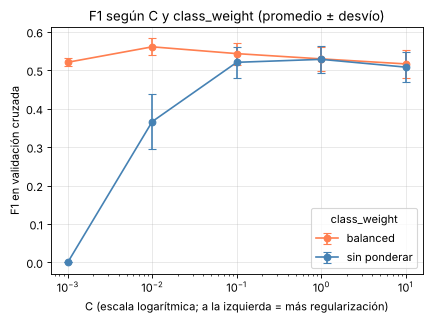

In [ ]:
plt.figure(figsize=(6, 4))
for cw, color, nombre in [('balanced', 'coral', 'balanced'), (None, 'steelblue', 'sin ponderar')]:
    if cw is None:
        filas = tabla_cv[tabla_cv['class_weight'] == 'sin ponderar']
    else:
        filas = tabla_cv[tabla_cv['class_weight'] == cw]
    filas = filas.sort_values('C')
    plt.errorbar(filas['C'], filas['F1 validación (promedio)'], yerr=filas['Desvío'],
                 marker='o', capsize=4, label=nombre, color=color)

plt.xscale('log')
plt.xlabel('C (escala logarítmica; a la izquierda = más regularización)')
plt.ylabel('F1 en validación cruzada')
plt.title('F1 según C y class_weight (promedio ± desvío)')
plt.legend(title='class_weight')
plt.grid(alpha=0.3)
plt.show()

**Resultado:** el mayor F1 de validación cruzada es `C = 0,01` con `class_weight='balanced'` (0,561, desvío entre partes 0,022).

**Por qué esa combinación:**
- **Se eligió por F1**, porque combina precisión y recall. La exactitud no sirve (decir siempre "No" acierta el 83 %).
- **`class_weight='balanced'`:** hay unos 5 "No" por cada "Sí". Sin ponderar, con `C` chico el modelo casi siempre responde "No" (F1 de 0 y 0,37). Con `balanced` el F1 nunca baja de 0,52 y es mayor o igual en todos los valores de `C` (tabla de arriba).
- **`C = 0,01`:** da el mayor F1; con valores más chicos o más grandes baja.
- **Diferencia chica:** frente a `C = 0,1` la ventaja es de 0,02, parecida al desvío (0,022).

**Decisión:** `C = 0,01` con `balanced`. Se eligió solo con datos de entrenamiento.

In [ ]:
# Elección fundamentada en la tabla y el gráfico
modelo_final = clone(pipe).set_params(modelo__C=0.01, modelo__class_weight='balanced')
modelo_final.fit(X_train, y_train);

,Exactitud,Precision,Recall,F1,ROC-AUC
"Referencia (siempre ""No"")",0.830,0.000,0.000,0.000,0.500
"Por defecto (C=1, sin ponderar)",0.858,0.630,0.403,0.492,0.826
"Elegido (C=0,01, balanced)",0.823,0.485,0.681,0.566,0.853


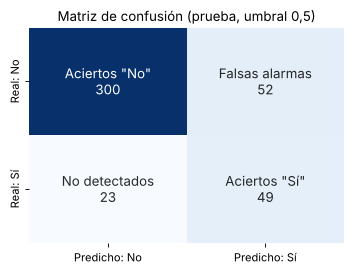

In [ ]:
def evaluar(modelo, umbral=0.5):
    # probabilidad de y=1 y clase predicha según el umbral
    proba = modelo.predict_proba(X_test)[:, 1]
    pred = (proba >= umbral).astype(int)
    return {'Exactitud': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, proba)}

modelo_defecto = pipe.fit(X_train, y_train)    # C = 1, sin ponderar clases

comparacion = pd.DataFrame({'Referencia (siempre "No")': [exactitud_base, 0, 0, 0, 0.5],
                            'Por defecto (C=1, sin ponderar)': evaluar(modelo_defecto).values(),
                            'Elegido (C=0,01, balanced)': evaluar(modelo_final).values()},
                           index=['Exactitud', 'Precision', 'Recall', 'F1', 'ROC-AUC']).T
display(comparacion.round(3))

matriz = confusion_matrix(y_test, modelo_final.predict(X_test))
tabla_matriz = pd.DataFrame(matriz, index=['Real: No', 'Real: Sí'], columns=['Predicho: No', 'Predicho: Sí'])
nombres = np.array([['Aciertos "No"\n' + str(matriz[0, 0]), 'Falsas alarmas\n' + str(matriz[0, 1])],
                    ['No detectados\n' + str(matriz[1, 0]), 'Aciertos "Sí"\n' + str(matriz[1, 1])]])

plt.figure(figsize=(4.5, 3.5))
sns.heatmap(tabla_matriz, annot=nombres, fmt='', cmap='Blues', cbar=False, annot_kws={'size': 12})
plt.title('Matriz de confusión (prueba, umbral 0,5)')
plt.tight_layout()
plt.show()


**Comparación** (prueba: 424 jóvenes, 72 "Sí"):
- **Referencia (siempre "No"):** exactitud 0,83 y recall 0. No detecta a ningún interesado.
- **Por defecto (`C = 1`, sin ponderar):** recall 0,40 y precisión 0,63. Detecta 4 de cada 10 interesados.
- **Elegido (`C = 0,01`, `balanced`):** recall 0,68 y precisión 0,49. Detecta casi 7 de cada 10 y mejora el F1 (0,57 frente a 0,49) y el ROC-AUC (0,85 frente a 0,83). Pierde exactitud (0,82) porque hace más falsas alarmas.

**Interpretación del modelo elegido:**
- **Matriz de confusión:** 49 aciertos "Sí", 52 falsas alarmas, 23 interesados no detectados y 300 aciertos "No".
- **Precisión 0,49:** de los 101 jóvenes para los que dijo "Sí", 49 lo son. Casi la mitad de sus "Sí" son falsas alarmas.
- **Recall 0,68:** de los 72 que declaran interés, detectó 49.
- **ROC-AUC 0,85:** se calculó con las probabilidades del modelo en la prueba (`roc_auc_score(y_test, proba)`) y no depende del umbral. Ante un joven con "Sí" y otro con "No", el modelo le asigna mayor probabilidad al "Sí" en 85 de cada 100 casos (0,5 sería azar).
- **F1 0,57:** se usó para comparar hiperparámetros. El umbral se define en la sección 8, priorizando el recall.

**Análisis:** la exactitud sola no sirve para juzgar el modelo, porque responder siempre "No" ya acierta el 83 %. Lo que mejora el modelo elegido es detectar a los interesados (recall de 0 a 0,68), y lo paga con más falsas alarmas. Esa es la compensación que se busca para el uso previsto, y se ajusta con el umbral en la sección 8.

## 8. Umbral de decisión
El modelo dice "Sí" cuando la probabilidad supera un umbral; hasta acá se usó 0,50. Un umbral más bajo detecta más interesados (sube el recall) con más falsas alarmas (baja la precisión); uno más alto hace lo contrario.

**Para qué se usa el modelo:** conocer qué jóvenes se interesan por Informática, Tecnología, Programación o Ciencia de Datos sirve para decidir dónde invertir recursos y qué acciones hacer para acercar a más jóvenes. Para eso, **dejar pasar a un joven interesado es más costoso que una falsa alarma**, porque un joven con perfil parecido al de los interesados también puede ser destinatario de esas acciones.

**Criterio de elección:** el umbral con mayor precisión entre los que detectan al menos 7 de cada 10 interesados (recall ≥ 0,70).

**Cómo se calcula:** para elegirlo sin usar la prueba, se calcula la probabilidad de cada joven del entrenamiento con validación cruzada (cada joven se predice con un modelo que no lo vio) y se mira cómo cambian las medidas.

**Por qué F1 para los hiperparámetros y recall para el umbral:** los hiperparámetros se compararon con F1 porque equilibra precisión y recall (con el recall solo, un modelo que dijera siempre "Sí" tendría el máximo). Una vez elegido el modelo, el umbral se ajusta según el uso, y ahí pesa más no dejar pasar interesados.

,Umbral,Precision,Recall,F1
0,0.20,0.239,0.962,0.383
1,0.25,0.267,0.944,0.416
2,0.30,0.302,0.916,0.454
3,0.35,0.336,0.889,0.488
4,0.40,0.367,0.843,0.511
5,0.45,0.398,0.798,0.531
6,0.50,0.431,0.760,0.550
7,0.55,0.462,0.683,0.551
8,0.60,0.510,0.638,0.567
9,0.65,0.565,0.578,0.571


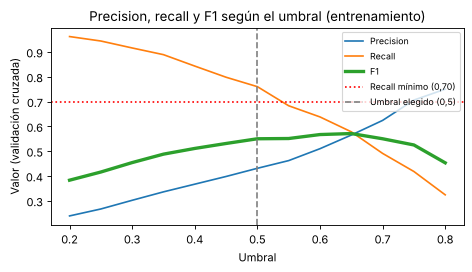

Umbral elegido (mayor precision con recall >= 0,70): 0.5


In [ ]:
# Probabilidad de cada joven del entrenamiento, calculada con validación cruzada
cv_umbral = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_cv = cross_val_predict(modelo_final, X_train, y_train, cv=cv_umbral, method='predict_proba')[:, 1]

# Precision, recall y F1 para cada umbral posible
filas = []
for u in np.arange(0.20, 0.81, 0.05):
    pred_u = (proba_cv >= u).astype(int)
    filas.append([u, precision_score(y_train, pred_u), recall_score(y_train, pred_u), f1_score(y_train, pred_u)])
tabla_umbral = pd.DataFrame(filas, columns=['Umbral', 'Precision', 'Recall', 'F1']).round(3)
display(tabla_umbral)

# Gráfico: las líneas marcan el recall mínimo pedido (0,70) y el umbral elegido (0,5)
plt.figure(figsize=(6, 3.5))
plt.plot(tabla_umbral['Umbral'], tabla_umbral['Precision'], label='Precision')
plt.plot(tabla_umbral['Umbral'], tabla_umbral['Recall'], label='Recall')
plt.plot(tabla_umbral['Umbral'], tabla_umbral['F1'], label='F1', linewidth=3)
plt.axhline(0.70, color='red', linestyle=':', label='Recall mínimo (0,70)')
plt.axvline(0.5, color='gray', linestyle='--', label='Umbral elegido (0,5)')
plt.xlabel('Umbral'); plt.ylabel('Valor (validación cruzada)')
plt.title('Precision, recall y F1 según el umbral (entrenamiento)')
plt.legend(loc='upper right', fontsize=8); plt.tight_layout(); plt.show()

# Criterio: mayor precision entre los umbrales con recall >= 0,70
candidatos = tabla_umbral[tabla_umbral['Recall'] >= 0.70]
umbral_elegido = candidatos.loc[candidatos['Precision'].idxmax(), 'Umbral']
print('Umbral elegido (mayor precision con recall >= 0,70):', umbral_elegido)

**Resultado:** al subir el umbral, la precisión sube (de 0,24 con 0,20 a 0,75 con 0,80) y el recall baja (de 0,96 a 0,32). El F1 es casi plano entre 0,50 y 0,70 (0,55 a 0,57), con el máximo en 0,65 (0,571).

**Decisión:** 0,50, el más alto que cumple recall ≥ 0,70 (0,76). Con 0,55 el recall baja a 0,68 y ya no cumple. Como el F1 casi no varía, la elección depende del error que se quiere evitar; el umbral de mayor F1 (0,65) deja pasar más interesados, por eso no se elige.

In [ ]:
# Ahora sí, en la prueba: umbral elegido frente al de mayor F1 (0,65)
res_umbral = pd.DataFrame({f'Umbral {umbral_elegido:.2f} (elegido)'.replace('.', ','): evaluar(modelo_final, umbral_elegido),
                           'Umbral 0,65 (mayor F1)': evaluar(modelo_final, 0.65)}).T
display(res_umbral.round(3))

for u in [umbral_elegido, 0.65]:
    pred_u = (modelo_final.predict_proba(X_test)[:, 1] >= u).astype(int)
    print(f'\n=== Umbral {u:.2f} ===')
    print('Matriz de confusión (filas: real No/Sí | columnas: predicho No/Sí):')
    print(confusion_matrix(y_test, pred_u))
    print(classification_report(y_test, pred_u, target_names=['No (y=0)', 'Sí (y=1)']))

,Exactitud,Precision,Recall,F1,ROC-AUC
"Umbral 0,50 (elegido)",0.823,0.485,0.681,0.566,0.853
"Umbral 0,65 (mayor F1)",0.866,0.623,0.528,0.571,0.853



=== Umbral 0.50 ===
Matriz de confusión (filas: real No/Sí | columnas: predicho No/Sí):
[[300  52]
 [ 23  49]]
              precision    recall  f1-score   support

    No (y=0)       0.93      0.85      0.89       352
    Sí (y=1)       0.49      0.68      0.57        72

    accuracy                           0.82       424
   macro avg       0.71      0.77      0.73       424
weighted avg       0.85      0.82      0.83       424


=== Umbral 0.65 ===
Matriz de confusión (filas: real No/Sí | columnas: predicho No/Sí):
[[329  23]
 [ 34  38]]
              precision    recall  f1-score   support

    No (y=0)       0.91      0.93      0.92       352
    Sí (y=1)       0.62      0.53      0.57        72

    accuracy                           0.87       424
   macro avg       0.76      0.73      0.75       424
weighted avg       0.86      0.87      0.86       424



**Evaluación en la prueba** (72 jóvenes interesados y 352 no interesados):
- **Umbral 0,50 (elegido):** detecta 49 de 72 (recall 0,68) y hace 52 falsas alarmas (precisión 0,49).
- **Umbral 0,65 (mayor F1):** detecta 38 de 72 (recall 0,53) y hace 23 falsas alarmas (precisión 0,62). La exactitud sube de 0,82 a 0,87.
- **Diferencia:** el F1 casi no cambia (0,566 y 0,571). Con 0,50 se detectan 11 interesados más (49 frente a 38), a cambio de 29 falsas alarmas más (52 frente a 23).
- **Aclaración:** en el entrenamiento (con validación cruzada) el umbral 0,50 dio un recall de 0,76, y en la prueba dio 0,68, algo por debajo del 0,70 pedido. Son jóvenes distintos, y con solo 72 interesados en la prueba el recall varía bastante entre grupos. El umbral se fijó con el entrenamiento y no se reajusta con la prueba, para que siga siendo una estimación independiente.

## 9. Variables que más pesan en el modelo
Los coeficientes indican cuánto aumenta (positivo) o reduce (negativo) la probabilidad de `y = 1` (querer estudiar Informática, Tecnología, Programación o Ciencia de Datos). Son pesos del modelo, no porcentajes. Las variables numéricas y ordinales están estandarizadas, así que se pueden comparar entre sí (con las de tipo sí/no la comparación es aproximada). Son asociaciones, no causas.

Mayores coeficientes positivos:
num_ord__P3_d             0.52
num_ord__P5_d             0.36
binarias__P8_3_f          0.36
binarias__P22_3           0.26
nominales__F4.SEXO_2.0    0.25
nominales__P11_d_4.0      0.22
binarias__P22_11          0.22
binarias__P32             0.17

Mayores coeficientes negativos:
nominales__P11_d_3.0     -0.27
nominales__F4.SEXO_1.0   -0.24
nominales__P11_a_3.0     -0.19
binarias__P8_2_f         -0.18
num_ord__P5_e            -0.18
nominales__P11_b_4.0     -0.15
num_ord__P6_f            -0.12
num_ord__F1.Edad         -0.12


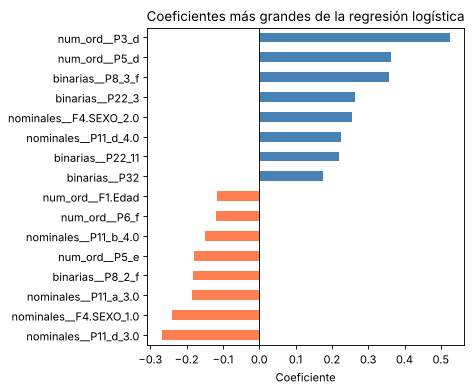

In [ ]:
nombres_columnas = modelo_final.named_steps['prep'].get_feature_names_out()
coeficientes = pd.Series(modelo_final.named_steps['modelo'].coef_[0], index=nombres_columnas).sort_values()

print('Mayores coeficientes positivos:'); print(coeficientes.tail(8)[::-1].round(2).to_string())
print('\nMayores coeficientes negativos:'); print(coeficientes.head(8).round(2).to_string())

extremos = pd.concat([coeficientes.head(8), coeficientes.tail(8)])
plt.figure(figsize=(6, 5))
extremos.plot(kind='barh', color=['coral' if v < 0 else 'steelblue' for v in extremos])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coeficientes más grandes de la regresión logística')
plt.xlabel('Coeficiente')
plt.tight_layout()
plt.show()

**Análisis:**
- **Lo que más pesa es el interés previo en informática:** querer hacer cursos de programación o robótica (`P3_d`, el mayor con 0,52), que guste la materia Informática (`P5_d`) y pensar que Computación "sirve para el futuro laboral" (`P8_3_f`).
- **También aumentan:** ser varón, asociar a quien trabaja en tecnología con "buen sueldo" (`P22_3`) o "creativo" (`P22_11`), querer participar en tutorías de olimpíadas de informática sin haberlo hecho (`P11_d_4`) y tener computadora en casa (`P32`).
- **Reducen:** no haber participado ni querer hacerlo en tutorías para olimpíadas de informática (`P11_d_3`) ni en talleres de robótica / programación (`P11_a_3`), ser mujer, pensar que Biología, Física o Química "sirven para el futuro laboral" (`P8_2_f`), que guste Biología (`P5_e`), querer participar en tutorías para olimpíadas de matemática sin haberlo hecho (`P11_b_4`), valorar la educación recibida en Física y Química (`P6_f`) y la edad (efecto chico).
- **Ojo:** varias de las más importantes (`P3_d`, `P5_d`, `P8_3_f`, `P11_*`) miden interés o experiencia en informática, muy cerca de lo que se quiere predecir. Se conocen antes de elegir carrera, así que no son fuga de información, pero parte de la capacidad del modelo viene de ahí.
- **Sexo:** que aparezca no significa que el sexo determine el interés. Refleja una diferencia que ya se veía en los datos de entrenamiento (declara interés el 29,3 % de los varones y el 9,4 % de las mujeres).

## 10. Guardar el modelo
Se guarda el modelo final (ya entrenado, con su preparación de datos incluida) en la carpeta `models/`, para poder usarlo después sin volver a entrenar.

In [ ]:
import joblib
os.makedirs(f'{raiz}/models', exist_ok=True)
joblib.dump(modelo_final, f'{raiz}/models/regresion_logistica.joblib')
print('Modelo guardado en models/regresion_logistica.joblib')

Modelo guardado en models/regresion_logistica.joblib


En Colab el archivo se guarda en la sesión: para conservarlo hay que descargarlo. En el repositorio queda en `models/`.

## 11. Conclusiones

- **Qué se hizo:** una regresión logística dentro de un `Pipeline` para predecir si un joven de 16 a 18 años declara que piensa estudiar Informática, Tecnología, Programación o Ciencia de Datos. Los hiperparámetros (`C` y `class_weight`) y el umbral se eligieron con validación cruzada sobre el entrenamiento; la prueba se usó solo para evaluar.
- **Resultado:** con `C = 0,01`, `class_weight='balanced'` y umbral 0,50, en la prueba el modelo logra ROC-AUC 0,85, F1 0,57, recall 0,68 y precisión 0,49: detecta 49 de los 72 interesados y se equivoca con 52 de los 352 que no lo estaban. Con umbral 0,65 detecta 38 de 72 y se equivoca con 23.
- **Qué mejoró el modelo:** ponderar las clases y regularizar bastante. El modelo por defecto detectaba 4 de cada 10 interesados (recall 0,40) y el elegido casi 7 de cada 10 (0,68). Supera a la referencia en recall y F1, no en exactitud.
- **Qué se asocia al interés:** querer hacer cursos de programación o robótica (`P3_d`) es lo que más pesa: declara interés el 53,4 % de quienes tienen mucho interés y el 5,0 % de quienes no tienen ninguno. Le siguen que guste Informática (`P5_d`) y pensar que Computación sirve para el futuro laboral (`P8_3_f`). Son asociaciones, no causas.
- **Cómo ayuda al problema:** permite identificar perfiles con más probabilidad de interés, para decidir dónde invertir recursos y orientar acciones. Se eligió un umbral que prioriza no dejar pasar a jóvenes interesados.
- **Qué no permite afirmar:** no predice qué carrera estudiará un joven, solo su intención declarada, y con 72 casos positivos en la prueba las métricas tienen un margen de error importante.

**Limitaciones**
- Muestra online y no probabilística: no se generaliza a todos los jóvenes del país.
- Quedan afuera los indecisos ("No sé aún") y quienes no piensan seguir estudiando.
- Predictores y objetivo se respondieron al mismo tiempo: no se sabe si lo declarado coincide con lo que después estudian.
- Varias variables importantes miden interés en informática, muy cerca del objetivo; no se probó el modelo sin ellas.
- Precisión moderada (0,49): casi la mitad de los "Sí" son falsas alarmas, aceptado a propósito.

**Qué falta hacer**
- Probar el modelo sin las variables más cercanas al objetivo (`P3_d`, `P5_d`, `P8_3_f`, `P11_*`).
- Compararlo con otros algoritmos.
- Seguir a los mismos jóvenes en el tiempo.
- Definir con quien use el modelo cuántas falsas alarmas se pueden aceptar.